# 🍌 Banana Leaf Disease Classification Using Deep Learning

## 0. Setup: imports, configuration and reproducibility

In [53]:
import os
import json
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score, balanced_accuracy_score)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

warnings.filterwarnings("ignore", category=UserWarning, module="PIL")
ImageFile.LOAD_TRUNCATED_IMAGES = True          # a few dataset JPEGs are slightly truncated
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# ---------------- configuration ----------------
SEED         = 42
IMG_SIZE     = (224, 224)          # MobileNetV2 native input size
BATCH_SIZE   = 32
CLASS_NAMES  = ["cordana", "healthy", "pestalotiopsis", "sigatoka"]   # alphabetical = label ids 0..3
CLASS_TO_ID  = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES  = len(CLASS_NAMES)
NOISE_STD    = 10.0                # Gaussian noise std on the 0-255 pixel scale (~4 %), training only
DATA_DIR     = None                # set manually e.g. Path(r"C:\data\OriginalSet") if auto-detection fails
OUTPUT_DIR   = Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)

# ---------------- reproducibility ----------------
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow version :", tf.__version__)
print("GPU devices        :", tf.config.list_physical_devices("GPU") or "none (training will run on CPU)")
print("Classes            :", CLASS_TO_ID)

TensorFlow version : 2.21.0
GPU devices        : none (training will run on CPU)
Classes            : {'cordana': 0, 'healthy': 1, 'pestalotiopsis': 2, 'sigatoka': 3}


# Task 1 – Load and explore the dataset in  

In [54]:
def find_dataset_root(class_names, max_depth=4):
    # Search common places for a folder that contains every class sub-folder.
    roots = [Path.cwd(), Path.cwd().parent, Path("/kaggle/input"), Path.home() / "Downloads"]
    skip = {"node_modules", "__pycache__", "venv", ".venv", "site-packages"}
    hits = []
    for root in roots:
        if not root.exists():
            continue
        base_depth = len(root.parts)
        for dirpath, dirnames, _ in os.walk(root):
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and d not in skip]
            if len(Path(dirpath).parts) - base_depth >= max_depth:
                dirnames[:] = []
            if all((Path(dirpath) / c).is_dir() for c in class_names):
                hits.append(Path(dirpath))
    hits = list(dict.fromkeys(hits))
    preferred = [h for h in hits if "originalset" in h.name.lower()]
    if preferred:
        return preferred[0]
    if hits:
        return hits[0]
    raise FileNotFoundError(
        "Dataset not found. Extract the Kaggle zip next to this notebook (folder 'OriginalSet') "
        "or set DATA_DIR manually in the setup cell.")

DATA_DIR = Path(DATA_DIR) if DATA_DIR else find_dataset_root(CLASS_NAMES)
print("Dataset folder:", DATA_DIR.resolve())

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
records = []
for cls in CLASS_NAMES:
    for p in sorted((DATA_DIR / cls).iterdir()):
        if p.is_file() and p.suffix.lower() in VALID_EXT:
            records.append({"filepath": str(p), "filename": p.name, "label": cls, "label_id": CLASS_TO_ID[cls]})

df = pd.DataFrame(records)
print(f"Images found: {len(df)}")
df.head()

Dataset folder: D:\Btech\Machine Learning\fistproject\OriginalSet
Images found: 937


,filepath,filename,label,label_id
0,d:\Btech\Machine Learning\fistproject\Original...,0.jpeg,cordana,0
1,d:\Btech\Machine Learning\fistproject\Original...,1.jpeg,cordana,0
2,d:\Btech\Machine Learning\fistproject\Original...,10.jpeg,cordana,0
3,d:\Btech\Machine Learning\fistproject\Original...,100.jpeg,cordana,0
4,d:\Btech\Machine Learning\fistproject\Original...,101.jpeg,cordana,0


### 1.2 Check that every image can be read, and inspect image sizes

In [55]:
unreadable, sizes, md5s = [], [], []
for path in df["filepath"]:
    try:
        with Image.open(path) as im:
            sizes.append(im.size)
            im.convert("RGB").load()
        md5s.append(hashlib.md5(Path(path).read_bytes()).hexdigest())
    except Exception as exc:                      # noqa: BLE001
        unreadable.append((path, str(exc)))
        sizes.append(None); md5s.append(None)

df["md5"] = md5s
print("Unreadable images :", len(unreadable))
print("Distinct image sizes (width, height):", pd.Series([s for s in sizes if s]).value_counts().to_dict())

if unreadable:
    df = df[~df["filepath"].isin([u[0] for u in unreadable])].reset_index(drop=True)
    print("Removed unreadable files ->", len(df), "images remain")

Unreadable images : 0
Distinct image sizes (width, height): {(224, 224): 937}


### 1.3 Display labelled samples from all four classes

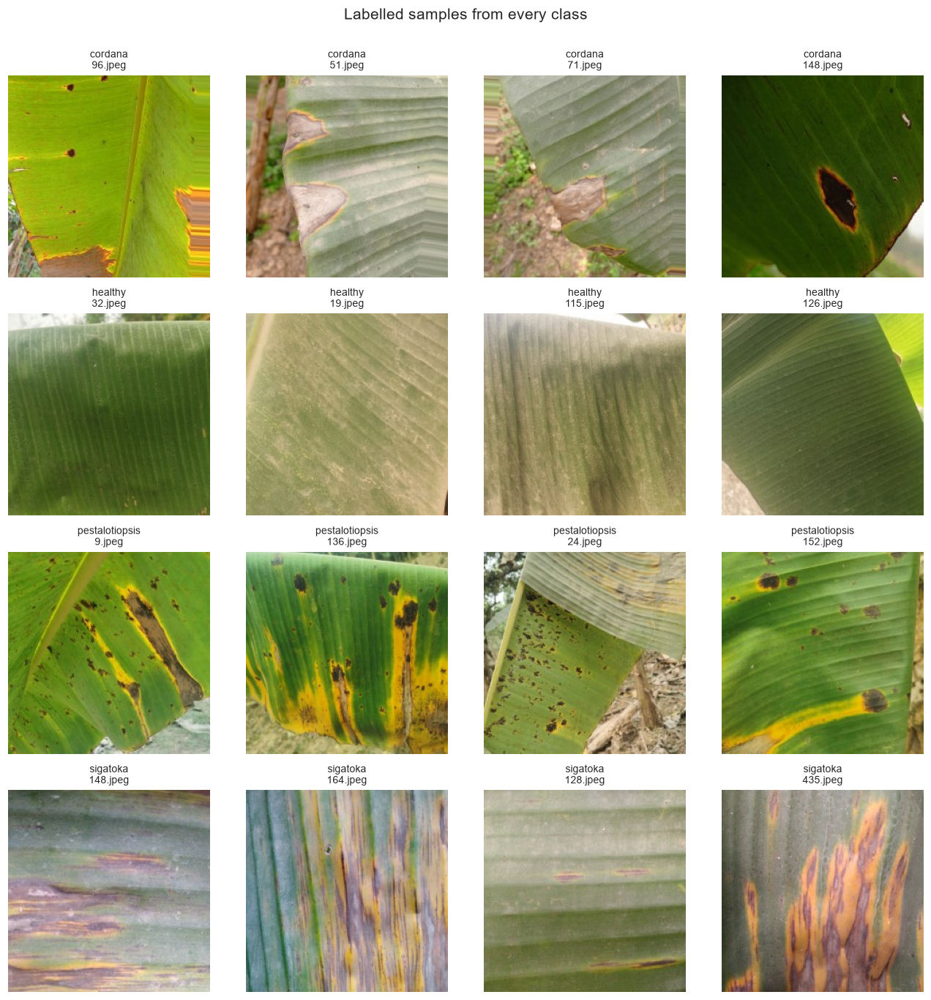

In [56]:
def show_class_samples(frame, n_per_class=4, seed=SEED, title="Labelled samples from every class"):
    fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(3 * n_per_class, 3.1 * NUM_CLASSES))
    for r, cls in enumerate(CLASS_NAMES):
        picks = frame[frame["label"] == cls].sample(n_per_class, random_state=seed)
        for c, (_, row) in enumerate(picks.iterrows()):
            with Image.open(row["filepath"]) as im:
                axes[r, c].imshow(im.convert("RGB"))
            axes[r, c].set_title(f"{row['label']}\n{row['filename']}", fontsize=9)
            axes[r, c].axis("off")
    fig.suptitle(title, fontsize=14, y=1.00)
    plt.tight_layout(); plt.show()

show_class_samples(df)

### 1.4 Count images per class (raw dataset)

,images,share_%
label,,
cordana,162,17.3
healthy,129,13.8
pestalotiopsis,173,18.5
sigatoka,473,50.5


Total: 937 | imbalance ratio (largest / smallest): 3.67


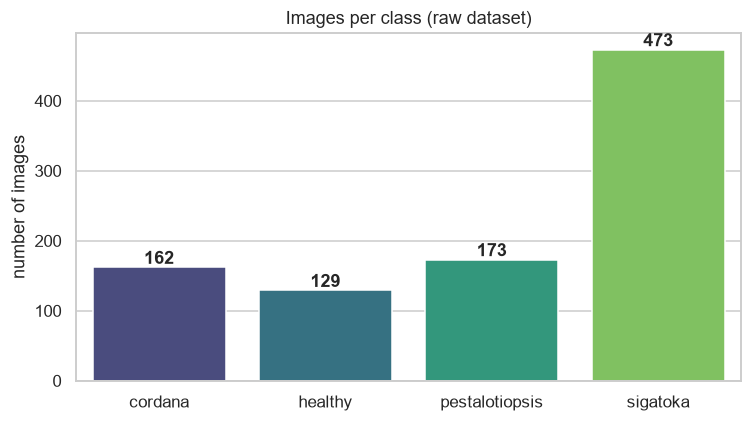

In [57]:
raw_counts = df["label"].value_counts().reindex(CLASS_NAMES)
raw_table = pd.DataFrame({"images": raw_counts, "share_%": (100 * raw_counts / raw_counts.sum()).round(1)})
display(raw_table)
print("Total:", raw_counts.sum(), "| imbalance ratio (largest / smallest):", round(raw_counts.max() / raw_counts.min(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=raw_counts.index, y=raw_counts.values, hue=raw_counts.index, palette="viridis", legend=False, ax=ax)
for i, v in enumerate(raw_counts.values):
    ax.text(i, v + 5, str(v), ha="center", fontweight="bold")
ax.set_title("Images per class (raw dataset)"); ax.set_ylabel("number of images"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 1.5 Data-quality check: exact duplicate images (data-leakage risk)

In [58]:
n_before = len(df)
dup_groups = df.groupby("md5")
dup_sizes = dup_groups.size()
dup_hashes = dup_sizes[dup_sizes > 1].index
conflicting = dup_groups["label"].nunique()
conflicting_hashes = conflicting[conflicting > 1].index

print(f"Duplicate groups found      : {len(dup_hashes)}")
print(f"Groups with conflicting labels: {len(conflicting_hashes)} (discarded completely)")
print("Duplicates per class        :", df[df['md5'].isin(dup_hashes)].groupby('label').size().to_dict())

df = df[~df["md5"].isin(conflicting_hashes)]
df = df.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"\nImages before: {n_before} -> after cleaning: {len(df)}  (removed {n_before - len(df)})")

clean_counts = df["label"].value_counts().reindex(CLASS_NAMES)
clean_table = pd.DataFrame({"raw": raw_counts, "clean": clean_counts,
                            "share_clean_%": (100 * clean_counts / clean_counts.sum()).round(1)})
display(clean_table)
print("Imbalance ratio after cleaning:", round(clean_counts.max() / clean_counts.min(), 2))

Duplicate groups found      : 39
Groups with conflicting labels: 1 (discarded completely)
Duplicates per class        : {'healthy': 77, 'pestalotiopsis': 1}

Images before: 937 -> after cleaning: 897  (removed 40)


,raw,clean,share_clean_%
label,,,
cordana,162,162,18.1
healthy,129,90,10.0
pestalotiopsis,173,172,19.2
sigatoka,473,473,52.7


Imbalance ratio after cleaning: 5.26


### 1.6 Discussion of the class distributions

# Task 2 – Preprocess the images and Resize all images consistently

In [59]:
def load_and_resize(path, size=IMG_SIZE):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(size, Image.Resampling.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

X = np.stack([load_and_resize(p) for p in df["filepath"]])
y = df["label_id"].to_numpy(dtype=np.int32)

print("Image tensor shape :", X.shape, "(images, height, width, channels)")
print("dtype / pixel range:", X.dtype, f"[{X.min()}, {X.max()}]")
print("Label vector shape :", y.shape)
assert X.shape[1:3] == IMG_SIZE, "All images must have the same size"

Image tensor shape : (897, 224, 224, 3) (images, height, width, channels)
dtype / pixel range: uint8 [0, 255]
Label vector shape : (897,)


### 2.2 Split into training, validation and test sets (70 % / 15 % / 15 %)

In [60]:
indices = np.arange(len(X))
idx_trainval, idx_test = train_test_split(indices, test_size=0.15, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15 / 0.85,
                                      stratify=y[idx_trainval], random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]
test_filenames   = df.loc[idx_test, "filename"].to_numpy()
test_filepaths   = df.loc[idx_test, "filepath"].to_numpy()

# ---- leakage checks: indices AND file fingerprints must be disjoint ----
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
h = df["md5"]
assert not (set(h[idx_train]) & set(h[idx_val])) and not (set(h[idx_train]) & set(h[idx_test])) and not (set(h[idx_val]) & set(h[idx_test]))
print("✔ No image appears in more than one split.\n")

split_table = pd.DataFrame({
    "train": pd.Series(y_train).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    "validation": pd.Series(y_val).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    "test": pd.Series(y_test).map(dict(enumerate(CLASS_NAMES))).value_counts(),
}).reindex(CLASS_NAMES)
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

total = len(X)
for name, arr in [("Training", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name:<10}: {len(arr):4d} images ({100 * len(arr) / total:.1f} %)")

✔ No image appears in more than one split.



,train,validation,test
cordana,114,24,24
healthy,62,14,14
pestalotiopsis,120,26,26
sigatoka,331,71,71
TOTAL,627,135,135


Training  :  627 images (69.9 %)
Validation:  135 images (15.1 %)
Test      :  135 images (15.1 %)


### 2.3 Prepare pixel values for the chosen model

In [61]:
sample = X_train[:8].astype("float32")
scaled = preprocess_input(sample.copy())
print(f"Before preprocessing : min={sample.min():.1f}, max={sample.max():.1f}  (0..255)")
print(f"After  preprocessing : min={scaled.min():.2f}, max={scaled.max():.2f}  (-1..1, as MobileNetV2 expects)")

Before preprocessing : min=0.0, max=255.0  (0..255)
After  preprocessing : min=-1.00, max=1.00  (-1..1, as MobileNetV2 expects)


### 2.4 Data augmentation – **training images only** (including Gaussian noise)
Augmentations simulate real field conditions: different orientations, camera distance, lighting, and sensor noise.

| Layer | Simulates |
|---|---|
| `RandomFlip` (horizontal + vertical) | leaf orientation |
| `RandomRotation(±15 %)` | camera angle |
| `RandomZoom(±15 %)`, `RandomTranslation(10 %)` | distance / framing |
| `RandomContrast`, `RandomBrightness` | sunlight and shadow |
| `GaussianNoise(σ = 10 / 255)` | sensor noise and low-quality phone cameras |

`GaussianNoise` and the other random layers are only active when called with `training=True`; the validation and test
pipelines below never call them.

In [62]:
augmenter = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15, fill_mode="reflect"),
    layers.RandomZoom((-0.15, 0.15), fill_mode="reflect"),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect"),
    layers.RandomContrast(0.20),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="train_augmentation")


def augment_batch(x):
    # Geometric/lighting augmentation + Gaussian sensor noise (std on the 0-255 pixel scale).
    # Keras 3's GaussianNoise layer only accepts std in [0, 1], so the noise is added explicitly here.
    x = augmenter(x, training=True)
    x = x + tf.random.normal(tf.shape(x), mean=0.0, stddev=NOISE_STD)
    return tf.clip_by_value(x, 0.0, 255.0)

# ---- class weights (computed from the TRAINING labels only) ----
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(cw)}
cw_vector = tf.constant(cw, dtype=tf.float32)
print("Class weights:", {CLASS_NAMES[i]: round(w, 3) for i, w in class_weights.items()})


def make_dataset(images, labels, training):
    # Build a tf.data pipeline. Augmentation + sample weights are used ONLY when training=True.
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)

    def _prepare(x, y_):
        x = tf.cast(x, tf.float32)
        if training:
            x = augment_batch(x)
        x = preprocess_input(x)
        if training:
            return x, y_, tf.gather(cw_vector, y_)       # (inputs, labels, sample_weights)
        return x, y_

    return ds.map(_prepare, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


train_ds      = make_dataset(X_train, y_train, training=True)     # augmented + weighted
train_eval_ds = make_dataset(X_train, y_train, training=False)    # clean copy, only for diagnosing over/underfitting
val_ds        = make_dataset(X_val,   y_val,   training=False)    # NOT augmented
test_ds       = make_dataset(X_test,  y_test,  training=False)    # NOT augmented
print("tf.data pipelines ready.")

Class weights: {'cordana': 1.375, 'healthy': 2.528, 'pestalotiopsis': 1.306, 'sigatoka': 0.474}
tf.data pipelines ready.


### 2.5 Visual proof: one training image vs. its augmented/noisy versions

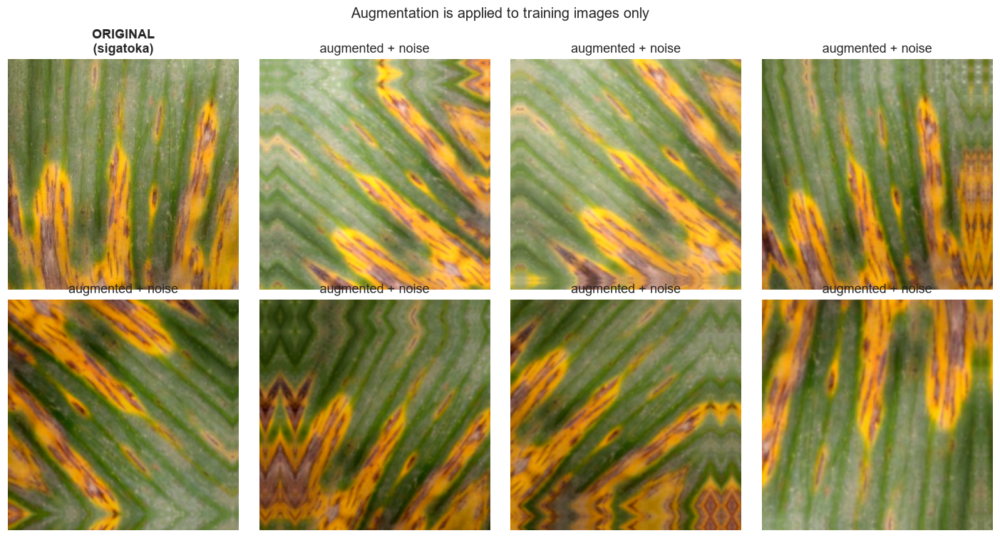

Validation pipeline deterministic (no augmentation): True


In [63]:
idx = 0
original = X_train[idx:idx + 1].astype("float32")
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
axes[0, 0].imshow(X_train[idx]); axes[0, 0].set_title(f"ORIGINAL\n({CLASS_NAMES[y_train[idx]]})", fontweight="bold")
for ax in axes.ravel()[1:]:
    aug = tf.clip_by_value(augmenter(original, training=True), 0, 255).numpy()[0].astype("uint8")
    ax.imshow(aug); ax.set_title("augmented + noise")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Augmentation is applied to training images only", fontsize=13)
plt.tight_layout(); plt.show()

# validation/test pipelines are deterministic: the same batch twice gives identical tensors
b1 = next(iter(val_ds))[0].numpy(); b2 = next(iter(val_ds))[0].numpy()
print("Validation pipeline deterministic (no augmentation):", np.allclose(b1, b2))

# Task 3 – Build the model: transfer learning with MobileNetV2 (18 marks)

### 3.1 Architecture
```
Input 224×224×3
  → MobileNetV2 backbone (ImageNet weights, no top)      ← feature extractor
  → GlobalAveragePooling2D                               ← 7×7×1280 → 1280 numbers
  → Dropout(0.3)
  → Dense(256, ReLU, L2 regularisation)
  → Dropout(0.4)
  → Dense(4, Softmax)                                     ← cordana / healthy / pestalotiopsis / sigatoka
```

In [64]:
def build_model(num_classes=NUM_CLASSES, input_shape=IMG_SIZE + (3,)):
    try:
        base = MobileNetV2(input_shape=input_shape, include_top=False, weights="imagenet")
        print("Loaded ImageNet pre-trained weights.")
    except Exception as exc:                                  # offline fallback so the notebook still runs
        print("⚠ Could not download ImageNet weights ->", exc)
        print("⚠ Falling back to random initialisation (accuracy will be much lower). Connect to the internet and re-run.")
        base = MobileNetV2(input_shape=input_shape, include_top=False, weights=None)
    base.trainable = False                                    # stage 1: backbone frozen

    inputs = keras.Input(shape=input_shape, name="leaf_image")
    x = base(inputs, training=False)                           # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="drop_1")(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4), name="dense_256")(x)
    x = layers.Dropout(0.4, name="drop_2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="disease_probabilities")(x)
    return keras.Model(inputs, outputs, name="banana_leaf_mobilenetv2"), base

model, base_model = build_model()
model.summary()

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
frozen    = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
print(f"\nInput shape  : {model.input_shape}")
print(f"Output shape : {model.output_shape}  -> 4 class probabilities")
print(f"Trainable parameters (stage 1): {trainable:,} | frozen: {frozen:,}")

Loaded ImageNet pre-trained weights.


Model: "banana_leaf_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_probabilities (Dense)   │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)


Input shape  : (None, 224, 224, 3)
Output shape : (None, 4)  -> 4 class probabilities
Trainable parameters (stage 1): 328,964 | frozen: 2,257,984


# Task 4 – Train the model (17 marks)

### 4.1 Loss, optimizer and metrics
* **Loss:** `SparseCategoricalCrossentropy` – labels are integers (0–3) and the model outputs probabilities.
* **Optimizer:** **Adam** (learning rate 1e-3 for the head; 2e-5 for fine-tuning).
* **Metric:** accuracy.
* **Callbacks:** `EarlyStopping` (monitor `val_loss`, patience 5, restores the best weights) and
  `ReduceLROnPlateau` (halves-and-more the learning rate when validation loss stalls).
* **Epoch budget:** up to 12 epochs (stage 1) + 18 epochs (stage 2) = **max 30 epochs**.

In [65]:
def make_callbacks(patience=5):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
print("Model compiled (stage 1): Adam(1e-3) | SparseCategoricalCrossentropy | accuracy")

Model compiled (stage 1): Adam(1e-3) | SparseCategoricalCrossentropy | accuracy


### 4.2 Stage 1 – train the new classifier head (backbone frozen), up to 12 epochs

In [66]:
MAX_STAGE1 = 12
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_STAGE1,
    callbacks=make_callbacks(patience=4),
    verbose=1,
)
stage1_epochs = len(history_1.history["loss"])
print(f"\nStage 1 finished after {stage1_epochs} epoch(s).")

Epoch 1/12


d:\Btech\Machine Learning\fistproject\python.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.6156 - loss: 1.1353 - val_accuracy: 0.7481 - val_loss: 0.6742 - learning_rate: 0.0010
Epoch 2/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8453 - loss: 0.5320 - val_accuracy: 0.8000 - val_loss: 0.5853 - learning_rate: 0.0010
Epoch 3/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.8581 - loss: 0.4348 - val_accuracy: 0.8889 - val_loss: 0.3907 - learning_rate: 0.0010
Epoch 4/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 877ms/step - accuracy: 0.8756 - loss: 0.4017 - val_accuracy: 0.9185 - val_loss: 0.3165 - learning_rate: 0.0010
Epoch 5/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 711ms/step - accuracy: 0.8565 - loss: 0.4369 - val_accuracy: 0.9037 - val_loss: 0.2934 - learning_rate: 0.0010
Epoch 6/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 656ms/step - accuracy: 0.8501 - loss: 0.4678 - val_accuracy: 0.9259 - val_loss: 0.2972 - learning_rate: 0.0010
Epoch 7/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 961ms/step - accuracy: 0.8788 - loss: 0.4185
Epoch 7: ReduceL

### 4.3 Stage 2 – fine-tune the top of the backbone (very small learning rate), up to 18 more epochs
Only the last 50 layers of MobileNetV2 are unfrozen. **BatchNormalization layers stay frozen**, which keeps the
statistics learned on ImageNet stable when fine-tuning on a small dataset.

In [67]:
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Trainable parameters in stage 2: {trainable:,}")

MAX_TOTAL = 30
history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_TOTAL,
    initial_epoch=stage1_epochs,
    callbacks=make_callbacks(patience=5),
    verbose=1,
)
total_epochs = stage1_epochs + len(history_2.history["loss"])
print(f"\nTraining finished after {total_epochs} epochs in total (maximum allowed: {MAX_TOTAL}).")

Trainable parameters in stage 2: 2,163,396
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 94s 3s/step - accuracy: 0.8900 - loss: 0.3609 - val_accuracy: 0.8370 - val_loss: 0.4525 - learning_rate: 2.0000e-05
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.9027 - loss: 0.2896 - val_accuracy: 0.9037 - val_loss: 0.3500 - learning_rate: 2.0000e-05
Epoch 12/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.9043 - loss: 0.2857 - val_accuracy: 0.9037 - val_loss: 0.3290 - learning_rate: 2.0000e-05
Epoch 13/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9107 - loss: 0.2636 - val_accuracy: 0.9259 - val_loss: 0.2736 - learning_rate: 2.0000e-05
Epoch 14/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.9362 - loss: 0.2542 - val_accuracy: 0.8667 - val_loss: 0.4184 - learning_rate: 2.0000e-05
Epoch 15/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9250 - loss: 0.2476  
Epoch 15: ReduceLROnPlateau reducing learning rate to 5.999999848427251e-06.
20/20 ━━━━━━━━━━━━━

### 4.4 Early-stopping report

In [68]:
history = {k: history_1.history[k] + history_2.history[k] for k in history_1.history if k in history_2.history}
hist_df = pd.DataFrame(history); hist_df.index += 1; hist_df.index.name = "epoch"
display(hist_df.round(4))

best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Total epochs run          : {total_epochs}")
print(f"Best epoch (lowest val_loss): {best_epoch}  | val_loss={min(history['val_loss']):.4f} | val_acc at that epoch={history['val_accuracy'][best_epoch-1]:.4f}")

if total_epochs < MAX_TOTAL:
    print(f"\nEarly stopping explanation: validation loss did not improve for several consecutive epochs after epoch {best_epoch}, "
          f"so training was stopped at epoch {total_epochs} and the weights of epoch {best_epoch} were restored. "
          "Continuing would only fit the training noise (overfitting) without improving validation performance.")
if total_epochs < 10:
    print("Note: training stopped before 10 epochs – the full history above is shown as required.")

hist_df.to_csv(OUTPUT_DIR / "training_history.csv")

,accuracy,loss,val_accuracy,val_loss,learning_rate
epoch,,,,,
1,0.6156,1.1353,0.7481,0.6742,0.0010
2,0.8453,0.5320,0.8000,0.5853,0.0010
3,0.8581,0.4348,0.8889,0.3907,0.0010
4,0.8756,0.4017,0.9185,0.3165,0.0010
5,0.8565,0.4369,0.9037,0.2934,0.0010
6,0.8501,0.4678,0.9259,0.2972,0.0010
7,0.8788,0.4185,0.9259,0.3131,0.0010
8,0.9091,0.3183,0.8741,0.3729,0.0003
9,0.9011,0.2786,0.9037,0.3351,0.0003


Total epochs run          : 18
Best epoch (lowest val_loss): 13  | val_loss=0.2736 | val_acc at that epoch=0.9259

Early stopping explanation: validation loss did not improve for several consecutive epochs after epoch 13, so training was stopped at epoch 18 and the weights of epoch 13 were restored. Continuing would only fit the training noise (overfitting) without improving validation performance.


### 4.5 Training and validation accuracy / loss curves
The dotted vertical line marks the beginning of fine-tuning (stage 2).

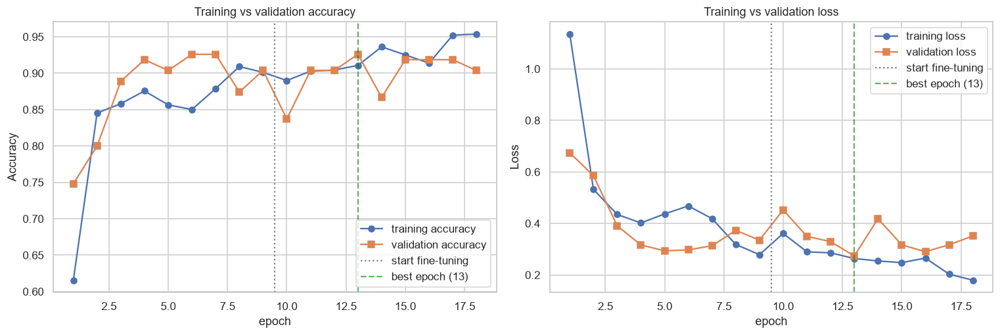

In [69]:
epochs_range = np.arange(1, total_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(epochs_range, history[metric], "o-", label=f"training {metric}")
    ax.plot(epochs_range, history[f"val_{metric}"], "s-", label=f"validation {metric}")
    ax.axvline(stage1_epochs + 0.5, color="gray", linestyle=":", label="start fine-tuning")
    ax.axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"best epoch ({best_epoch})")
    ax.set_title(f"Training vs validation {title.lower()}"); ax.set_xlabel("epoch"); ax.set_ylabel(title); ax.legend()
plt.tight_layout(); plt.show()

In [70]:
# ---- automatic interpretation of the curves ----
tr_acc, va_acc = history["accuracy"][best_epoch - 1], history["val_accuracy"][best_epoch - 1]
tr_loss, va_loss = history["loss"][best_epoch - 1], history["val_loss"][best_epoch - 1]
print("INTERPRETATION")
print(f"- At the best epoch ({best_epoch}) training accuracy is {tr_acc:.3f} and validation accuracy is {va_acc:.3f} (gap {tr_acc - va_acc:+.3f}).")
print(f"- Training loss {tr_loss:.3f} vs validation loss {va_loss:.3f}. Training metrics are measured on AUGMENTED + NOISY images with dropout active, "
      "so they are often *harder* than validation images; a validation accuracy that is close to or above training accuracy is therefore normal and healthy.")
print(f"- Validation accuracy improved by {history['val_accuracy'][-1] - history['val_accuracy'][0]:+.3f} between the first and last epoch.")
if tr_acc - va_acc > 0.08:
    print("- The gap is large -> signs of overfitting (the model memorises training images).")
else:
    print("- The gap is small -> the model generalises well; no strong sign of overfitting.")
if stage1_epochs < total_epochs:
    jump = max(history["val_accuracy"][stage1_epochs:]) - max(history["val_accuracy"][:stage1_epochs])
    print(f"- Fine-tuning (stage 2) changed the best validation accuracy by {jump:+.3f} compared with training only the head.")

INTERPRETATION
- At the best epoch (13) training accuracy is 0.911 and validation accuracy is 0.926 (gap -0.015).
- Training loss 0.264 vs validation loss 0.274. Training metrics are measured on AUGMENTED + NOISY images with dropout active, so they are often *harder* than validation images; a validation accuracy that is close to or above training accuracy is therefore normal and healthy.
- Validation accuracy improved by +0.156 between the first and last epoch.
- The gap is small -> the model generalises well; no strong sign of overfitting.
- Fine-tuning (stage 2) changed the best validation accuracy by +0.000 compared with training only the head.




### 5.1 Test loss and accuracy

In [71]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"TEST LOSS     : {test_loss:.4f}")
print(f"TEST ACCURACY : {test_acc:.4f}  ({test_acc * 100:.2f} %)")

y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print(f"Balanced accuracy (mean recall per class): {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1-score                          : {f1_score(y_test, y_pred, average='macro'):.4f}")

TEST LOSS     : 0.2200
TEST ACCURACY : 0.9407  (94.07 %)
Balanced accuracy (mean recall per class): 0.9166
Macro F1-score                          : 0.9161


### 5.2 Confusion matrix (all class names)

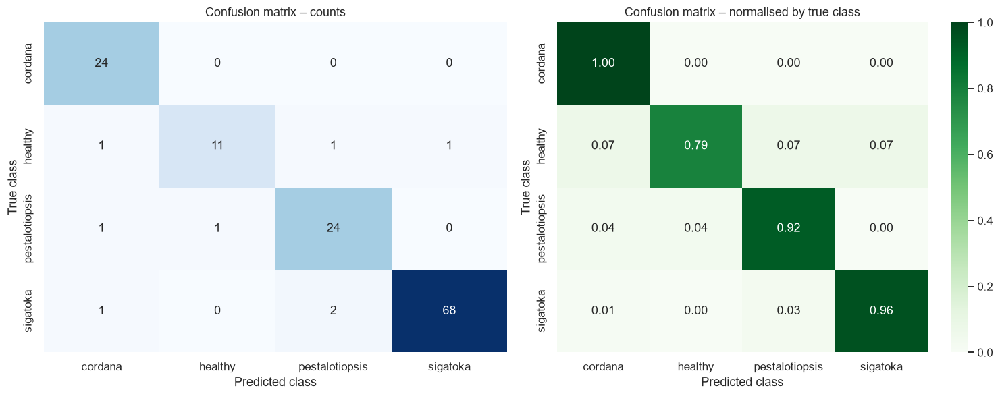

In [72]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], cbar=False)
axes[0].set_title("Confusion matrix – counts")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion matrix – normalised by true class")
for ax in axes:
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
plt.tight_layout(); plt.show()

### 5.3 Classification report (precision, recall, F1-score)

In [73]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
report_df = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)).T
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")

                precision    recall  f1-score   support

       cordana     0.8889    1.0000    0.9412        24
       healthy     0.9167    0.7857    0.8462        14
pestalotiopsis     0.8889    0.9231    0.9057        26
      sigatoka     0.9855    0.9577    0.9714        71

      accuracy                         0.9407       135
     macro avg     0.9200    0.9166    0.9161       135
  weighted avg     0.9426    0.9407    0.9404       135



### 5.4 Error analysis

Misclassified test images: 8 of 135


,filename,true_class,predicted_class,confidence
6,14.jpeg,sigatoka,pestalotiopsis,0.9174
7,128.jpeg,healthy,sigatoka,0.8396
119,294.jpeg,sigatoka,cordana,0.8254
22,80.jpeg,pestalotiopsis,cordana,0.7046
61,404.jpeg,sigatoka,pestalotiopsis,0.5983
13,75.jpeg,pestalotiopsis,healthy,0.5931
80,10.jpeg,healthy,cordana,0.5586
82,35.jpeg,healthy,pestalotiopsis,0.5361



Most frequent confusions (true -> predicted):
true_class      predicted_class
sigatoka        pestalotiopsis     2
healthy         pestalotiopsis     1
                cordana            1
                sigatoka           1
pestalotiopsis  cordana            1
                healthy            1
sigatoka        cordana            1


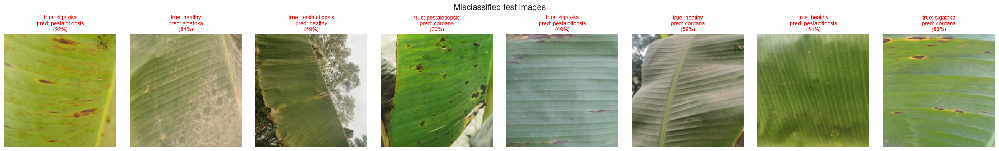

In [74]:
errors = pd.DataFrame({
    "filename": test_filenames,
    "true_class": [CLASS_NAMES[i] for i in y_test],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_prob.max(axis=1).round(4),
})
wrong = errors[errors["true_class"] != errors["predicted_class"]]
print(f"Misclassified test images: {len(wrong)} of {len(errors)}")
if len(wrong):
    display(wrong.sort_values("confidence", ascending=False))
    print("\nMost frequent confusions (true -> predicted):")
    print(wrong.groupby(["true_class", "predicted_class"]).size().sort_values(ascending=False).to_string())

    pos = np.where(y_test != y_pred)[0][:8]
    fig, axes = plt.subplots(1, len(pos), figsize=(3 * len(pos), 3.5), squeeze=False)
    for ax, i in zip(axes[0], pos):
        ax.imshow(X_test[i]); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[y_pred[i]]}\n({y_prob[i].max():.0%})", fontsize=9, color="red")
    plt.suptitle("Misclassified test images", y=1.02); plt.tight_layout(); plt.show()
else:
    print("No misclassification on the test set.")

In [75]:
# per-class weakest point + confidence analysis
per_class_recall = pd.Series(np.diag(cm) / cm.sum(axis=1), index=CLASS_NAMES)
print("Recall per class:\n", per_class_recall.round(3).to_string())
print(f"\nWeakest class (lowest recall): {per_class_recall.idxmin()} ({per_class_recall.min():.3f})")
correct_conf = errors.loc[errors['true_class'] == errors['predicted_class'], 'confidence'].mean()
print(f"Mean confidence on correct predictions : {correct_conf:.3f}")
if len(wrong):
    print(f"Mean confidence on wrong predictions   : {wrong['confidence'].mean():.3f}  (lower = the model 'knows' when it is unsure)")

Recall per class:
 cordana           1.000
healthy           0.786
pestalotiopsis    0.923
sigatoka          0.958

Weakest class (lowest recall): healthy (0.786)
Mean confidence on correct predictions : 0.935
Mean confidence on wrong predictions   : 0.697  (lower = the model 'knows' when it is unsure)


## evaluate a trained model, compare its performance on training, validation, and test data, and identify underfitting or overfitting.

In [76]:
tr_loss_c, tr_acc_c = model.evaluate(train_eval_ds, verbose=0)
va_loss_c, va_acc_c = model.evaluate(val_ds, verbose=0)
summary = pd.DataFrame({"loss": [tr_loss_c, va_loss_c, test_loss], "accuracy": [tr_acc_c, va_acc_c, test_acc]},
                       index=["train (clean)", "validation", "test"]).round(4)
display(summary)

gap = tr_acc_c - test_acc
print(f"Train–test accuracy gap: {gap:+.4f}")
if tr_acc_c < 0.80 and test_acc < 0.80:
    verdict = "UNDERFITTING – both training and test accuracy are low; the model is too simple or under-trained."
elif gap > 0.08:
    verdict = "OVERFITTING – training accuracy is much higher than test accuracy; the model memorises training images."
else:
    verdict = "GOOD FIT – high accuracy on all three sets with a small gap; the model generalises well (no significant over- or underfitting)."
print("\nCONCLUSION:", verdict)

,loss,accuracy
train (clean),0.1948,0.9585
validation,0.2736,0.9259
test,0.2200,0.9407


Train–test accuracy gap: +0.0178

CONCLUSION: GOOD FIT – high accuracy on all three sets with a small gap; the model generalises well (no significant over- or underfitting).


### 5.6 Robustness check: does the model survive noisy / badly lit photos

,accuracy,macro_F1
condition,,
clean test set,0.9407,0.9161
Gaussian noise σ=10,0.9333,0.9023
Gaussian noise σ=20,0.8889,0.8420
Gaussian noise σ=30,0.6667,0.5881
Gaussian noise σ=40,0.5704,0.3948
darker (×0.6),0.9481,0.9243
brighter (×1.4),0.9259,0.8903


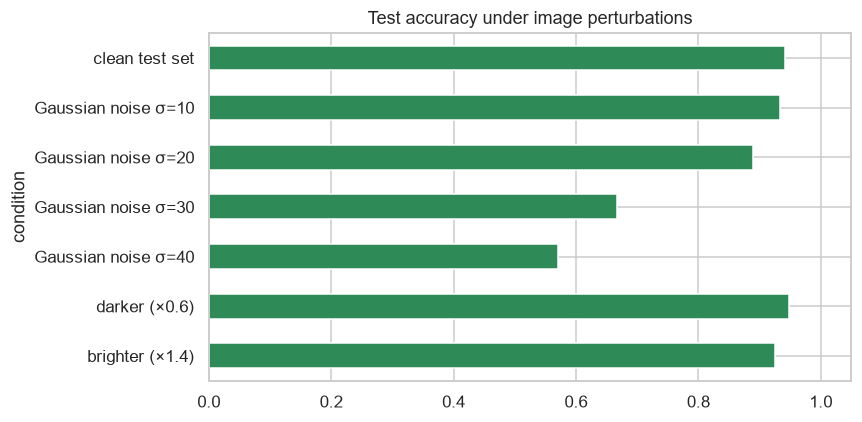

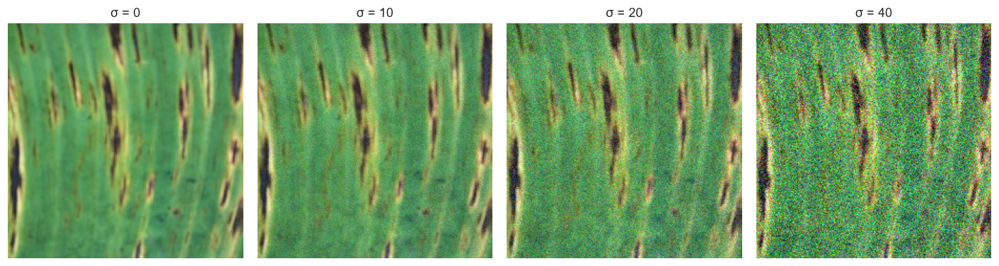

In [77]:
def evaluate_perturbed(fn):
    xs = fn(X_test.astype("float32"))
    xs = np.clip(xs, 0, 255)
    ds = tf.data.Dataset.from_tensor_slices(xs).batch(BATCH_SIZE).map(preprocess_input)
    pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    return accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")

rng = np.random.default_rng(SEED)
rows = [("clean test set", *evaluate_perturbed(lambda a: a))]
for sigma in [10, 20, 30, 40]:
    rows.append((f"Gaussian noise σ={sigma}", *evaluate_perturbed(lambda a, s=sigma: a + rng.normal(0, s, a.shape))))
rows.append(("darker (×0.6)", *evaluate_perturbed(lambda a: a * 0.6)))
rows.append(("brighter (×1.4)", *evaluate_perturbed(lambda a: a * 1.4)))
robust = pd.DataFrame(rows, columns=["condition", "accuracy", "macro_F1"]).set_index("condition").round(4)
display(robust)

ax = robust["accuracy"].plot(kind="barh", figsize=(8, 4), color="seagreen")
ax.set_xlim(0, 1.05); ax.set_title("Test accuracy under image perturbations"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

# example of what the noisy test images look like
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, s in zip(axes, [0, 10, 20, 40]):
    img = np.clip(X_test[0].astype("float32") + rng.normal(0, s, X_test[0].shape), 0, 255).astype("uint8")
    ax.imshow(img); ax.set_title(f"σ = {s}"); ax.axis("off")
plt.tight_layout(); plt.show()



### 6.1 Test images with true and predicted classes
Green title = correct prediction, red title = wrong prediction.

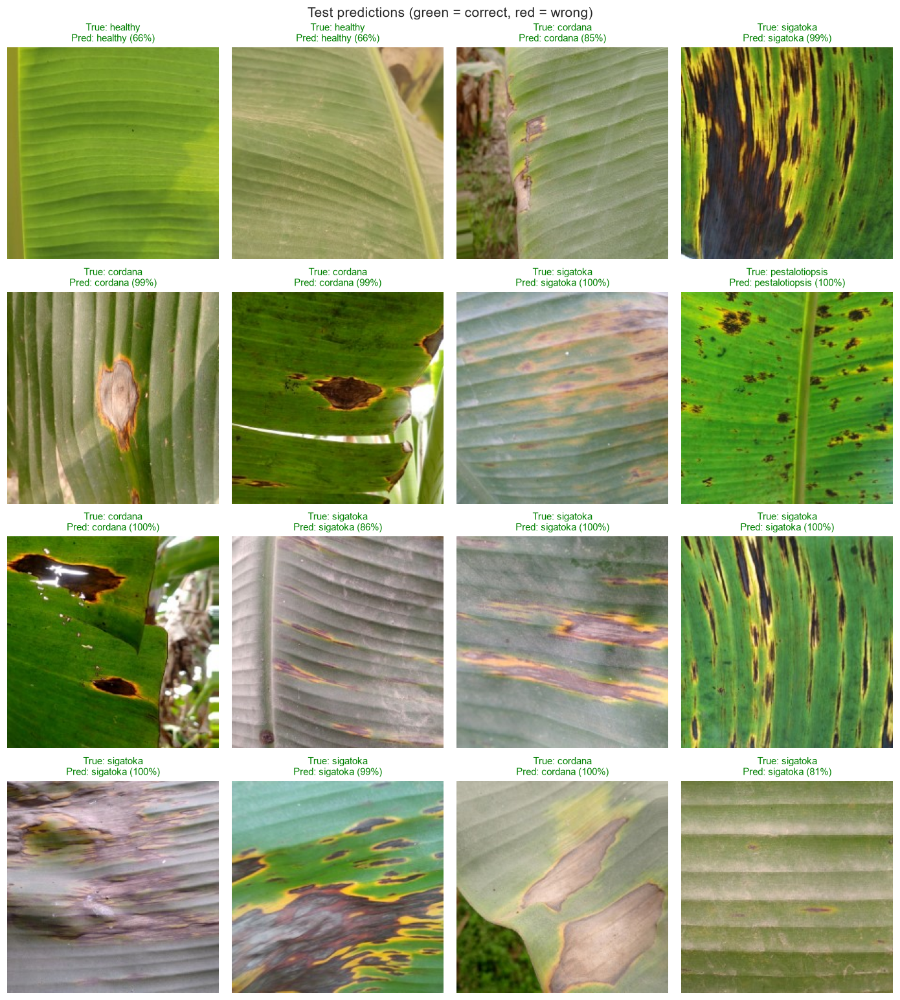

In [78]:
n_show = 16
show_idx = np.random.default_rng(SEED).choice(len(X_test), size=min(n_show, len(X_test)), replace=False)
cols = 4; rows_ = int(np.ceil(len(show_idx) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.6 * rows_))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), show_idx):
    ax.imshow(X_test[i])
    ok = y_test[i] == y_pred[i]
    ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({y_prob[i].max():.0%})",
                 color="green" if ok else "red", fontsize=10)
plt.suptitle("Test predictions (green = correct, red = wrong)", fontsize=14)
plt.tight_layout(); plt.show()

### 6.2 Save the trained model

In [79]:
MODEL_PATH = OUTPUT_DIR / "banana_leaf_mobilenetv2.keras"
model.save(MODEL_PATH)
with open(OUTPUT_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)
print(f"✔ Model saved successfully as: {MODEL_PATH.name}  (full path: {MODEL_PATH.resolve()})")

# sanity check: the reloaded model must reproduce exactly the same predictions
reloaded = keras.models.load_model(MODEL_PATH)
same = np.allclose(reloaded.predict(test_ds, verbose=0), y_prob, atol=1e-5)
print("Reloaded model gives identical predictions:", same)

✔ Model saved successfully as: banana_leaf_mobilenetv2.keras  (full path: D:\Btech\Machine Learning\fistproject\outputs\banana_leaf_mobilenetv2.keras)
Reloaded model gives identical predictions: True


### 6.3 Save the predictions to CSV (filename, true class, predicted class)

In [80]:
pred_df = pd.DataFrame({
    "image_filename": test_filenames,
    "true_class": [CLASS_NAMES[i] for i in y_test],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_prob.max(axis=1).round(4),
    "correct": y_test == y_pred,
})
CSV_PATH = OUTPUT_DIR / "test_predictions.csv"
pred_df.to_csv(CSV_PATH, index=False)
print(f"✔ Predictions saved to: {CSV_PATH.name}  ({len(pred_df)} test images)")
pred_df.head(10)

✔ Predictions saved to: test_predictions.csv  (135 test images)


,image_filename,true_class,predicted_class,confidence,correct
0,62.jpeg,sigatoka,sigatoka,0.9998,True
1,132.jpeg,sigatoka,sigatoka,0.9787,True
2,94.jpeg,cordana,cordana,0.9960,True
3,130.jpeg,pestalotiopsis,pestalotiopsis,0.9998,True
4,50.jpeg,pestalotiopsis,pestalotiopsis,0.9938,True
5,26.jpeg,sigatoka,sigatoka,0.8543,True
6,14.jpeg,sigatoka,pestalotiopsis,0.9174,False
7,128.jpeg,healthy,sigatoka,0.8396,False
8,79.jpeg,sigatoka,sigatoka,0.9870,True
9,145.jpeg,cordana,cordana,0.9959,True


### 6.4 Final summary

In [81]:
print("=" * 62)
print(" FINAL RESULTS – Banana Leaf Disease Classification")
print("=" * 62)
print(f" Model              : MobileNetV2 transfer learning (2-stage training)")
print(f" Images (clean)     : {len(X)}  | train {len(X_train)} / val {len(X_val)} / test {len(X_test)}")
print(f" Epochs run         : {total_epochs} (best epoch {best_epoch})")
print(f" Test loss          : {test_loss:.4f}")
print(f" Test accuracy      : {test_acc * 100:.2f} %")
print(f" Balanced accuracy  : {balanced_accuracy_score(y_test, y_pred) * 100:.2f} %")
print(f" Macro F1-score     : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f" Fit diagnosis      : {verdict.split(' – ')[0]}")
print("=" * 62)
print("Saved files:", *sorted(p.name for p in OUTPUT_DIR.iterdir()), sep="\n  - ")

 FINAL RESULTS – Banana Leaf Disease Classification
 Model              : MobileNetV2 transfer learning (2-stage training)
 Images (clean)     : 897  | train 627 / val 135 / test 135
 Epochs run         : 18 (best epoch 13)
 Test loss          : 0.2200
 Test accuracy      : 94.07 %
 Balanced accuracy  : 91.66 %
 Macro F1-score     : 0.9161
 Fit diagnosis      : GOOD FIT
Saved files:
  - banana_leaf_mobilenetv2.keras
  - class_names.json
  - classification_report.csv
  - test_predictions.csv
  - training_history.csv
